In [1]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

In [2]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [3]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [4]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", max_retries=6)

In [6]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}
    

In [7]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

In [8]:
def to_text(content):
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        return "".join(
            p if isinstance(p, str) else p.get("text", "")
            for p in content
        )
    return str(content)

In [9]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = to_text(llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content).strip()

    return {"sections": [section_md]}

In [10]:
import re
from pathlib import Path

def reducer(state: State) -> dict:

    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # ---- save to file ----
    safe = re.sub(r'[\\/:*?"<>|]', "", title).strip().lower().replace(" ", "_")
    filename = safe + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [11]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

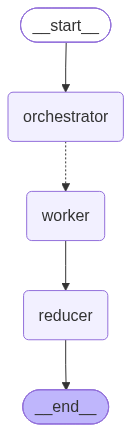

In [12]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [13]:
out = app.invoke({"topic": "Evolution of chat gpt from 2020 to 2026", "sections": []})

In [14]:
import re
from pathlib import Path

title = out["plan"].blog_title
safe = re.sub(r'[\\/:*?"<>|]', "", title).strip().lower().replace(" ", "_")
Path(safe + ".md").write_text(out["final"], encoding="utf-8")
print("Saved:", safe + ".md")

Saved: the_evolution_of_chatgpt_from_its_2020_debut_to_2026_innovations.md


In [15]:
print(out["final"])

# The Evolution of ChatGPT: From Its 2020 Debut to 2026 Innovations

## Introduction – Why ChatGPT’s Journey Matters

Conversational AI has moved from a niche research curiosity to a foundational layer of modern digital experiences. In just a few short years, ChatGPT has become the most recognizable embodiment of this shift, reshaping how we **search for information**, **create content**, **learn new skills**, and **interact with software**. Its influence stretches across:

- **Technology** – powering everything from code assistants and customer‑service bots to real‑time translation and creative co‑writing tools.  
- **Business** – enabling new productivity workflows, reducing support costs, and opening revenue streams built around AI‑augmented services.  
- **Society** – democratizing access to advanced language models, sparking debates on ethics, bias, and the future of work, and inspiring a wave of AI literacy.

This timeline will walk you through the pivotal moments that defined Ch